# Indoor Location Prediction Using Wi-Fi Signals (Phase 1)

AML Project 9, Section D

Team: Rishi Raj, Aditya Samadhiya, Yash Yadav, Kaustubh Ranjan Mishra, Yash Raj

Goal: from one Wi-Fi scan (signal strength of 520 access points) predict
1. the building (3 classes)
2. the floor (0 to 4)
3. the position (longitude, latitude in metres)

Dataset: UJIIndoorLoc from the UCI repository. Run `python scripts/download_data.py` once to download it.

Models used: Linear/Logistic Regression, k-NN, Random Forest.

The helper code for loading data, features, models and metrics is in `src/indoorloc/`. Everything else (EDA, plots, cross validation, evaluation) is done in this notebook.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GroupKFold

from indoorloc.data import load_raw, load_splits, split_xy, WAP_COLS, NOT_DETECTED
from indoorloc.features import FingerprintFeatures
from indoorloc.models import IndependentModel, HierarchicalModel
from indoorloc.metrics import summarize, positioning_errors, hierarchical_breakdown, per_group_error

plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 3)

## 1. Load the data

In [2]:
train_raw = load_raw("train")   # trainingData.csv
test = load_raw("test")         # validationData.csv, we use it as the test set

print("train:", train_raw.shape)
print("test :", test.shape)
train_raw.iloc[:5, list(range(6)) + list(range(520, 529))]

train: (19937, 529)
test : (1111, 529)


,WAP001,WAP002,WAP003,WAP004,WAP005,WAP006,LONGITUDE,LATITUDE,FLOOR,BUILDINGID,SPACEID,RELATIVEPOSITION,USERID,PHONEID,TIMESTAMP
0,100,100,100,100,100,100,-7541.264,4.865e+06,2,1,106,2,2,23,1371713733
1,100,100,100,100,100,100,-7536.621,4.865e+06,2,1,106,2,2,23,1371713691
2,100,100,100,100,100,100,-7519.152,4.865e+06,2,1,103,2,2,23,1371714095
3,100,100,100,100,100,100,-7524.570,4.865e+06,2,1,102,2,2,23,1371713807
4,100,100,100,100,100,100,-7632.144,4.865e+06,0,0,122,2,11,13,1369909710


Columns WAP001 to WAP520 are signal strengths in dBm. A real reading is between -104 and 0 (closer to 0 means stronger).
The value +100 means the access point was not detected in that scan.

In [3]:
W = train_raw[WAP_COLS].to_numpy()
heard = W != NOT_DETECTED

print("fraction of values that are +100 (not heard):", round(1 - heard.mean(), 4))
print("weakest real reading:", W[heard].min(), " strongest real reading:", W[heard].max())
print("APs heard per scan: mean", round(heard.sum(axis=1).mean(), 1), " max", heard.sum(axis=1).max())
print("APs never heard in training:", (~heard.any(axis=0)).sum())

fraction of values that are +100 (not heard): 0.9654
weakest real reading: -104  strongest real reading: 0
APs heard per scan: mean 18.0  max 51
APs never heard in training: 55


## 2. Cleaning (training set only)

In [4]:
print("duplicate rows:", train_raw.duplicated().sum())
print("scans where no AP was heard:", (~heard).all(axis=1).sum())

train, _, report = load_splits()   # drops both
print(report)

duplicate rows: 637
scans where no AP was heard: 76


{'rows_in': 19937, 'duplicates_dropped': 637, 'empty_scans_dropped': 73, 'rows_out': 19227}


We remove exact duplicate rows and scans with no AP heard. The test set is left exactly as given so our numbers can be compared with other papers.

## 3. Exploratory data analysis

### 3.1 Where the scans were taken

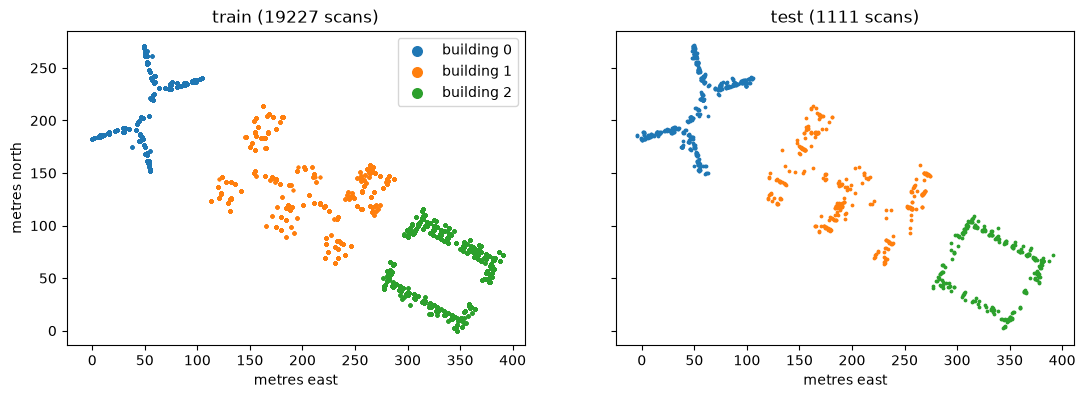

In [5]:
x0, y0 = train.LONGITUDE.min(), train.LATITUDE.min()   # shift so axes start near 0 metres

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True, sharey=True)
for b in range(3):
    t = train[train.BUILDINGID == b]
    ax[0].scatter(t.LONGITUDE - x0, t.LATITUDE - y0, s=3, label=f"building {b}")
    v = test[test.BUILDINGID == b]
    ax[1].scatter(v.LONGITUDE - x0, v.LATITUDE - y0, s=3, label=f"building {b}")
ax[0].set_title(f"train ({len(train)} scans)")
ax[1].set_title(f"test ({len(test)} scans)")
for a in ax:
    a.set_xlabel("metres east")
    a.set_aspect("equal")
ax[0].set_ylabel("metres north")
ax[0].legend(markerscale=4)
plt.show()

### 3.2 Samples per building and floor

In [6]:
counts = pd.DataFrame({
    "train": train.groupby(["BUILDINGID", "FLOOR"]).size(),
    "test": test.groupby(["BUILDINGID", "FLOOR"]).size(),
}).fillna(0).astype(int)
counts["train %"] = (counts.train / counts.train.sum() * 100).round(1)
counts["test %"] = (counts.test / counts.test.sum() * 100).round(1)
counts

train  test  train %  test %
BUILDINGID FLOOR                              
0          0       1056    78      5.5     7.0
           1       1356   208      7.1    18.7
           2       1443   165      7.5    14.9
           3       1390    85      7.2     7.7
1          0       1333    30      6.9     2.7
           1       1266   143      6.6    12.9
           2       1396    87      7.3     7.8
           3        909    47      4.7     4.2
2          0       1906    24      9.9     2.2
           1       2161   111     11.2    10.0
           2       1576    54      8.2     4.9
           3       2708    40     14.1     3.6
           4        727    39      3.8     3.5

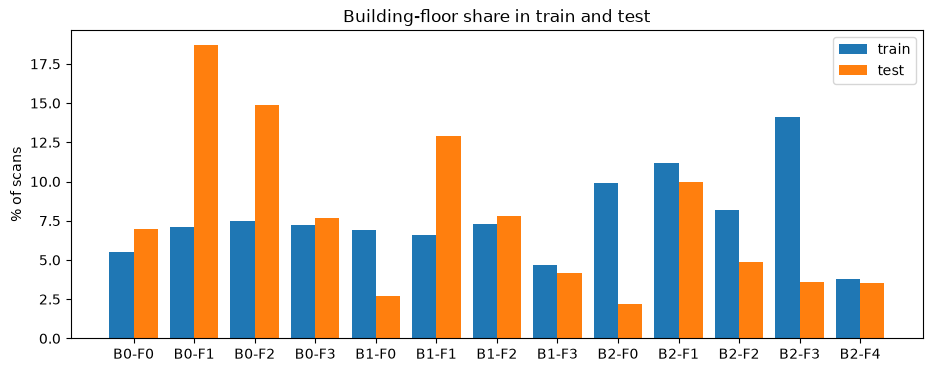

In [7]:
labels = [f"B{b}-F{f}" for b, f in counts.index]
x = np.arange(len(counts))
plt.figure(figsize=(11, 4))
plt.bar(x - 0.2, counts["train %"], width=0.4, label="train")
plt.bar(x + 0.2, counts["test %"], width=0.4, label="test")
plt.xticks(x, labels)
plt.ylabel("% of scans")
plt.title("Building-floor share in train and test")
plt.legend()
plt.show()

Training is fairly balanced. The test set has much more building 0 (about 48% vs 27%).

### 3.3 Signal strengths and how many APs a scan hears

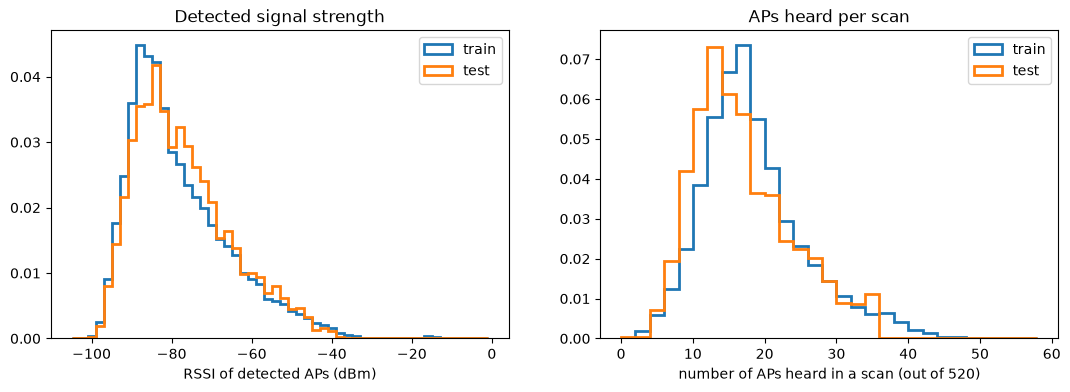

In [8]:
Wtr = train[WAP_COLS].to_numpy()
Wte = test[WAP_COLS].to_numpy()
htr, hte = Wtr != NOT_DETECTED, Wte != NOT_DETECTED

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
bins = np.arange(-105, 1, 2)
ax[0].hist(Wtr[htr], bins=bins, density=True, histtype="step", linewidth=2, label="train")
ax[0].hist(Wte[hte], bins=bins, density=True, histtype="step", linewidth=2, label="test")
ax[0].set_xlabel("RSSI of detected APs (dBm)")
ax[0].set_title("Detected signal strength")
ax[0].legend()

bins = np.arange(0, 60, 2)
ax[1].hist(htr.sum(axis=1), bins=bins, density=True, histtype="step", linewidth=2, label="train")
ax[1].hist(hte.sum(axis=1), bins=bins, density=True, histtype="step", linewidth=2, label="test")
ax[1].set_xlabel("number of APs heard in a scan (out of 520)")
ax[1].set_title("APs heard per scan")
ax[1].legend()
plt.show()

### 3.4 The data is very sparse

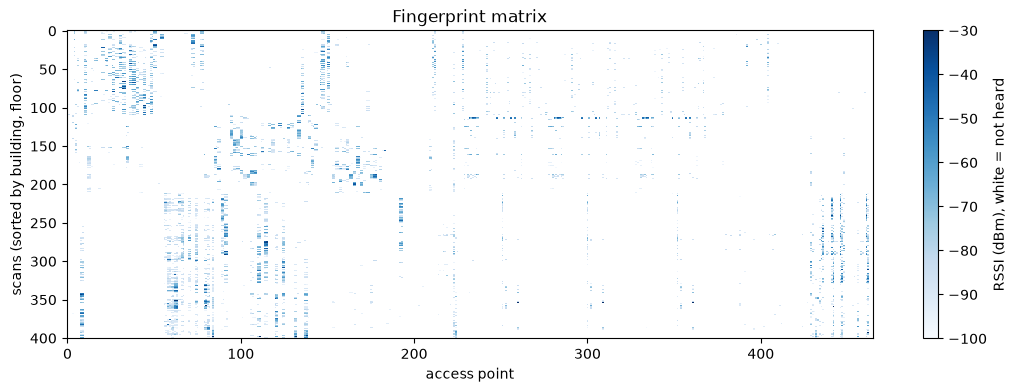

In [9]:
# take about 400 scans sorted by building and floor, and only APs that are heard at least once
order = np.argsort(train.BUILDINGID.to_numpy() * 10 + train.FLOOR.to_numpy(), kind="stable")
rows = order[::len(order) // 400]
cols = np.flatnonzero(htr.any(axis=0))
img = np.where(htr[np.ix_(rows, cols)], Wtr[np.ix_(rows, cols)], np.nan)

plt.figure(figsize=(13, 4))
plt.imshow(img, aspect="auto", cmap="Blues", vmin=-100, vmax=-30, interpolation="nearest")
plt.colorbar(label="RSSI (dBm), white = not heard")
plt.xlabel("access point")
plt.ylabel("scans (sorted by building, floor)")
plt.title("Fingerprint matrix")
plt.show()

Most of the matrix is empty. The blocks show that each building has its own set of access points.

### 3.5 In how many buildings is each AP heard?

0     55
1    323
2    139
3      3
Name: number of APs, dtype: int64


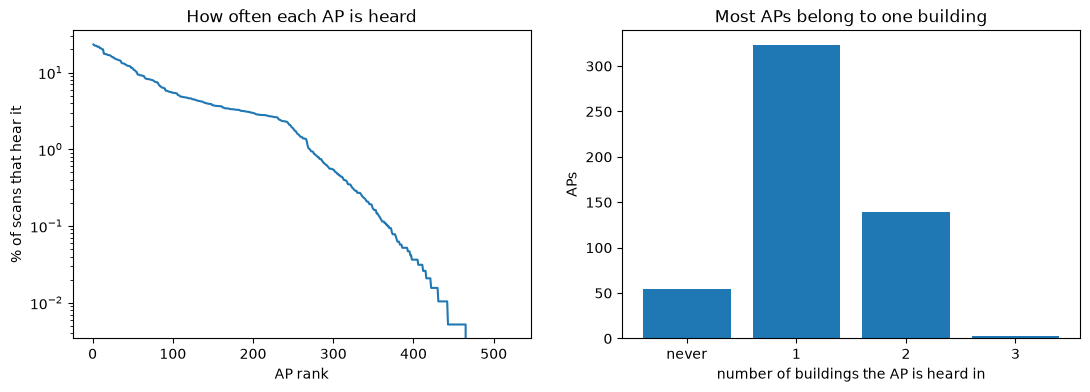

In [10]:
n_buildings = np.array([train.loc[htr[:, j], "BUILDINGID"].nunique() for j in range(520)])
print(pd.Series(n_buildings).value_counts().sort_index().rename("number of APs"))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
freq = np.sort(htr.mean(axis=0))[::-1] * 100
ax[0].plot(np.arange(1, 521), freq)
ax[0].set_yscale("log")
ax[0].set_xlabel("AP rank")
ax[0].set_ylabel("% of scans that hear it")
ax[0].set_title("How often each AP is heard")
ax[1].bar(["never", "1", "2", "3"], [(n_buildings == k).sum() for k in range(4)])
ax[1].set_xlabel("number of buildings the AP is heard in")
ax[1].set_ylabel("APs")
ax[1].set_title("Most APs belong to one building")
plt.show()

### 3.6 Floors share the same x-y area

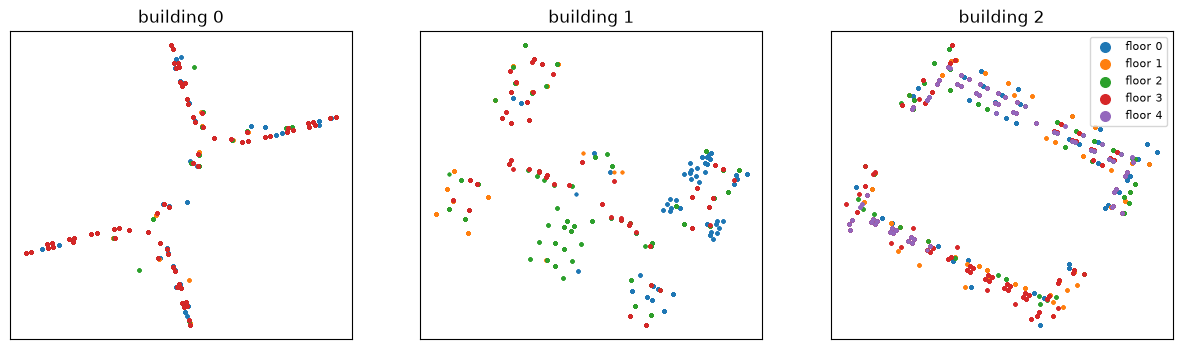

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for b in range(3):
    t = train[train.BUILDINGID == b]
    for f in sorted(t.FLOOR.unique()):
        s = t[t.FLOOR == f]
        ax[b].scatter(s.LONGITUDE, s.LATITUDE, s=3, label=f"floor {f}")
    ax[b].set_title(f"building {b}")
    ax[b].set_xticks([]); ax[b].set_yticks([])
ax[2].legend(markerscale=4, fontsize=8)
plt.show()

Position alone cannot tell the floor, so the floor has to come from the signals.

### 3.7 Users and phones

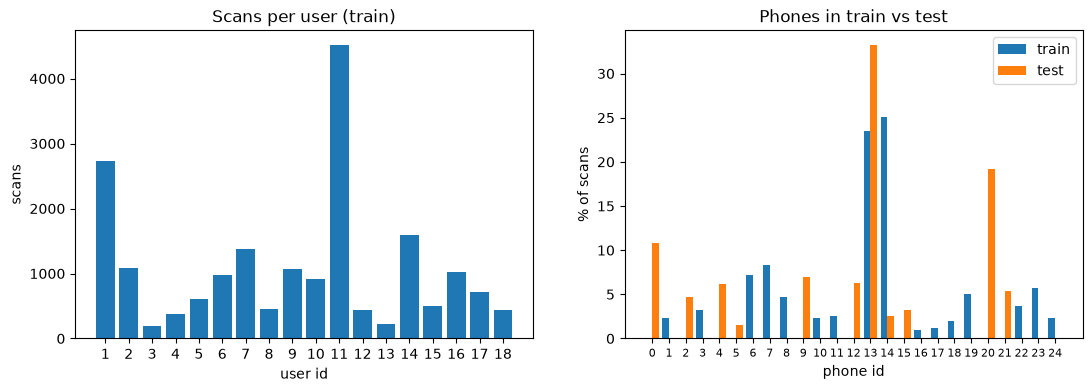

test phones: 11  not in training: 9
test scans from phones seen in training: 35.7%
training users with their own phone: 18 of 18


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
u = train.USERID.value_counts().sort_index()
ax[0].bar(u.index.astype(str), u.values)
ax[0].set_xlabel("user id")
ax[0].set_ylabel("scans")
ax[0].set_title("Scans per user (train)")

p = pd.DataFrame({"train": train.PHONEID.value_counts(normalize=True),
                  "test": test.PHONEID.value_counts(normalize=True)}).fillna(0).sort_index() * 100
x = np.arange(len(p))
ax[1].bar(x - 0.2, p.train, 0.4, label="train")
ax[1].bar(x + 0.2, p.test, 0.4, label="test")
ax[1].set_xticks(x, p.index.astype(str), fontsize=8)
ax[1].set_xlabel("phone id")
ax[1].set_ylabel("% of scans")
ax[1].set_title("Phones in train vs test")
ax[1].legend()
plt.show()

new_phones = set(test.PHONEID) - set(train.PHONEID)
print("test phones:", test.PHONEID.nunique(), " not in training:", len(new_phones))
print("test scans from phones seen in training: %.1f%%" % (test.PHONEID.isin(set(train.PHONEID)).mean() * 100))
print("training users with their own phone:", (train.groupby("USERID").PHONEID.nunique() == 1).sum(), "of", train.USERID.nunique())

### 3.8 Suspicious readings

scans with a reading above -30 dBm: 492
USERID  PHONEID
6       19         430
14      7           51
3       16           5
10      8            2
15      11           2
Name: count, dtype: int64


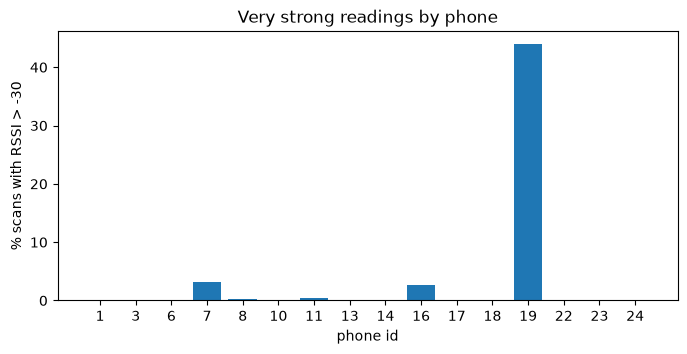

In [13]:
strong = (htr & (Wtr > -30)).any(axis=1)
print("scans with a reading above -30 dBm:", strong.sum())
print(train.loc[strong, ["USERID", "PHONEID"]].value_counts().head())

share = pd.Series(strong, index=train.index).groupby(train.PHONEID).mean() * 100
plt.figure(figsize=(8, 3.5))
plt.bar(share.index.astype(str), share.values)
plt.xlabel("phone id")
plt.ylabel("% scans with RSSI > -30")
plt.title("Very strong readings by phone")
plt.show()

Almost all of them come from phone 19 (user 6). Readings above -30 dBm are not realistic indoors. Later we check if removing them helps.

### 3.9 PCA

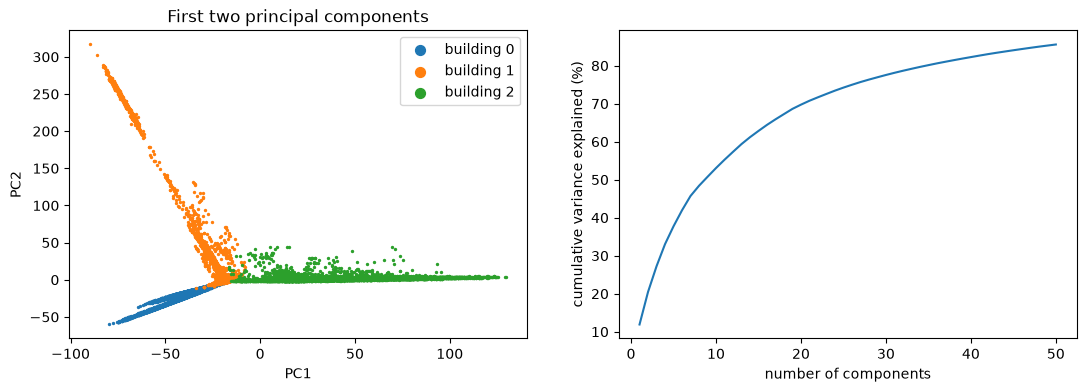

variance explained by 50 components: 85.6%


In [14]:
fe_pca = FingerprintFeatures(representation="raw", add_indicators=False, add_summary=False).fit(Wtr)
pca = PCA(n_components=50, random_state=0).fit(fe_pca.transform(Wtr))
Z = pca.transform(fe_pca.transform(Wtr))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for b in range(3):
    m = train.BUILDINGID.to_numpy() == b
    ax[0].scatter(Z[m, 0], Z[m, 1], s=2, label=f"building {b}")
ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2")
ax[0].set_title("First two principal components")
ax[0].legend(markerscale=5)
ax[1].plot(np.arange(1, 51), np.cumsum(pca.explained_variance_ratio_) * 100)
ax[1].set_xlabel("number of components")
ax[1].set_ylabel("cumulative variance explained (%)")
plt.show()
print("variance explained by 50 components: %.1f%%" % (pca.explained_variance_ratio_.sum() * 100))

## 4. Feature engineering

Main step: replace +100 (not heard) with -105 dBm. Not heard means the signal is too weak, so it should be weaker than every real value (the weakest is -104). If we keep +100 the model thinks the AP is the strongest one.

The value -105 and the list of APs to keep are computed on the training data only, then used unchanged on the test data.

In [15]:
Xtr, ytr, mtr = split_xy(train)
Xte, yte, mte = split_xy(test)

fe = FingerprintFeatures(representation="raw", add_indicators=False, add_summary=False).fit(Xtr)
print("value used for not heard:", fe.floor_)
print("APs kept:", len(fe.keep_), "of 520")
print("first scan, first 10 kept APs:", fe.transform(Xtr[:1])[0, :10])

value used for not heard: -105.0
APs kept: 465 of 520
first scan, first 10 kept APs: [-105. -105. -105. -105. -105. -105. -105. -105. -105. -105.]


We also tried other versions of the features:
- positive: shift so not heard = 0
- powed: compress weak signals (Torres-Sospedra et al. 2015)
- raw + a heard/not heard flag for every AP
- raw + flags + scan summary (number of APs heard, strongest, mean, std, ids of the 3 strongest APs)

They are compared with cross validation below.

## 5. Cross validation by user

People take scans in groups at the same place, so a random split would put almost identical scans in both train and validation. We use GroupKFold with USERID. The users in the validation fold never appear in the training fold.

All choices (features, k, max_features) are made with this CV. The test set is only used once at the end.

In [16]:
groups = mtr["USERID"].to_numpy()
folds = list(GroupKFold(n_splits=5).split(Xtr, groups=groups))

def cv_score(make_model):
    scores = []
    for tr_idx, va_idx in folds:
        model = make_model().fit(Xtr[tr_idx], ytr.iloc[tr_idx].reset_index(drop=True))
        scores.append(summarize(ytr.iloc[va_idx].reset_index(drop=True), model.predict(Xtr[va_idx])))
    return pd.DataFrame(scores).mean()

Metric used to compare: the mean position error on the held-out users, in metres. Lower is better. Building and floor accuracy are shown next to it.

### 5.1 Which features?

In [17]:
feature_versions = {
    "raw (not heard = -105)": dict(representation="raw", add_indicators=False, add_summary=False),
    "positive": dict(representation="positive", add_indicators=False, add_summary=False),
    "powed": dict(representation="powed", add_indicators=False, add_summary=False),
    "raw + heard flags": dict(representation="raw", add_indicators=True, add_summary=False),
    "raw + flags + summary": dict(representation="raw", add_indicators=True, add_summary=True),
}

rows = []
for name, cfg in feature_versions.items():
    s = cv_score(lambda cfg=cfg: HierarchicalModel("rf", features=FingerprintFeatures(**cfg), n_estimators=200))
    rows.append({"features": name, "model": "RF per-building", "cv_error_m": s.mean_error_m, "cv_floor_acc": s.building_floor_acc})
for name in ["raw (not heard = -105)", "positive", "powed", "raw + heard flags"]:
    cfg = feature_versions[name]
    s = cv_score(lambda cfg=cfg: IndependentModel("knn", features=FingerprintFeatures(**cfg), k=5))
    rows.append({"features": name, "model": "k-NN (k=5)", "cv_error_m": s.mean_error_m, "cv_floor_acc": s.building_floor_acc})
feat_cv = pd.DataFrame(rows)
feat_cv

,features,model,cv_error_m,cv_floor_acc
0,raw (not heard = -105),RF per-building,13.621,0.708
1,positive,RF per-building,13.621,0.708
2,powed,RF per-building,14.011,0.705
3,raw + heard flags,RF per-building,13.991,0.710
4,raw + flags + summary,RF per-building,14.366,0.721
5,raw (not heard = -105),k-NN (k=5),11.778,0.723
6,positive,k-NN (k=5),11.778,0.723
7,powed,k-NN (k=5),15.089,0.730
8,raw + heard flags,k-NN (k=5),11.763,0.723


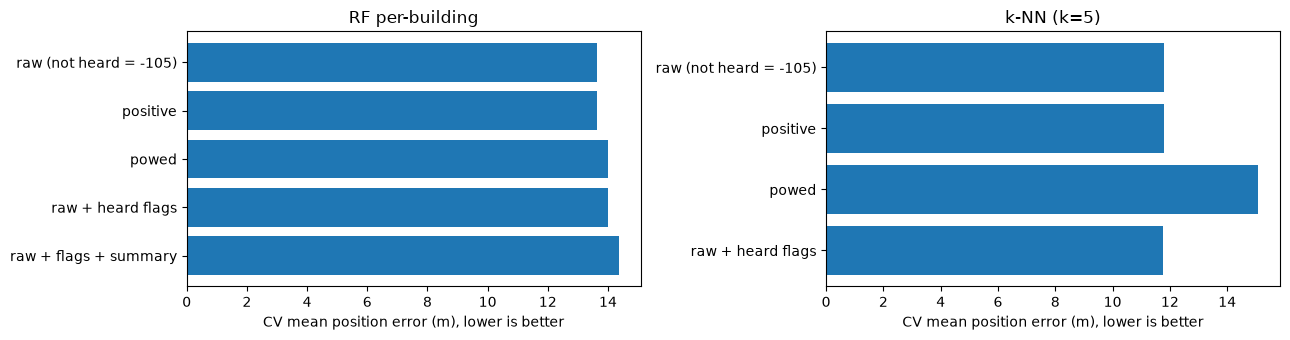

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
for a, model in zip(ax, ["RF per-building", "k-NN (k=5)"]):
    d = feat_cv[feat_cv.model == model]
    a.barh(d.features, d.cv_error_m)
    a.invert_yaxis()
    a.set_xlabel("CV mean position error (m), lower is better")
    a.set_title(model)
plt.tight_layout()
plt.show()

- raw and positive give exactly the same score. Positive is just raw + 105. A tree only checks "value > threshold", and adding the same number to everything keeps the order. For k-NN, adding the same number to both scans does not change the distance between them.
- No version is clearly better in CV (for k-NN the flags version differs by 0.02 m, which is noise), so we keep the simple raw features for every model. Features are chosen once, with the Random Forest, and used for all models.

In [19]:
best_features = dict(representation="raw", add_indicators=False, add_summary=False)

### 5.2 Choosing k for k-NN

In [20]:
knn_rows = []
for k in [1, 3, 5, 7, 11]:
    s = cv_score(lambda k=k: IndependentModel("knn", features=FingerprintFeatures(**best_features), k=k))
    knn_rows.append({"k": k, "cv_error_m": s.mean_error_m, "cv_floor_acc": s.building_floor_acc})
knn_cv = pd.DataFrame(knn_rows)
knn_cv

,k,cv_error_m,cv_floor_acc
0,1,12.921,0.724
1,3,12.101,0.723
2,5,11.778,0.723
3,7,11.805,0.723
4,11,11.928,0.721


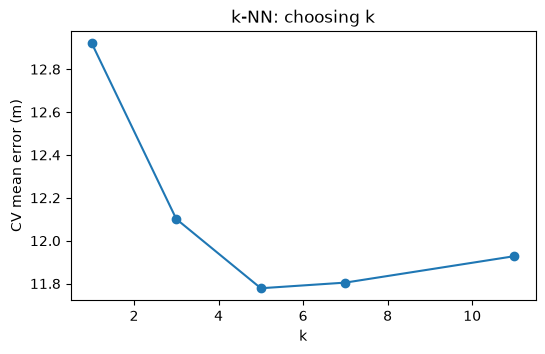

best k: 5


In [21]:
plt.figure(figsize=(6, 3.5))
plt.plot(knn_cv.k, knn_cv.cv_error_m, marker="o")
plt.xlabel("k")
plt.ylabel("CV mean error (m)")
plt.title("k-NN: choosing k")
plt.show()
best_k = int(knn_cv.loc[knn_cv.cv_error_m.idxmin(), "k"])
print("best k:", best_k)

### 5.3 Choosing max_features for Random Forest

In [22]:
rf_rows = []
for mf in ["sqrt", 0.1, 0.3]:
    s = cv_score(lambda mf=mf: HierarchicalModel("rf", features=FingerprintFeatures(**best_features),
                                                  max_features=mf, n_estimators=300))
    rf_rows.append({"max_features": mf, "cv_error_m": s.mean_error_m, "cv_floor_acc": s.building_floor_acc})
rf_cv = pd.DataFrame(rf_rows)
rf_cv

,max_features,cv_error_m,cv_floor_acc
0,sqrt,13.552,0.709
1,0.1,14.380,0.716
2,0.3,15.575,0.709


In [23]:
best_mf = rf_cv.loc[rf_cv.cv_error_m.idxmin(), "max_features"]
print("best max_features:", best_mf)

best max_features: sqrt


### 5.4 How many trees?

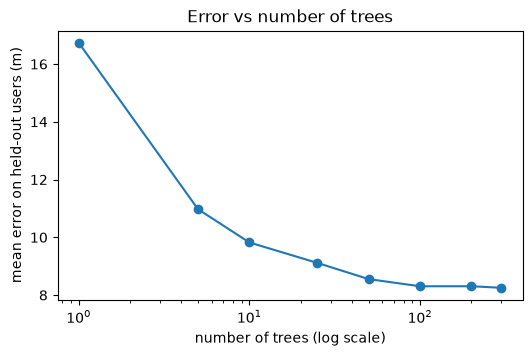

,trees,error_m,floor_acc
0,1,16.735,0.692
1,5,10.973,0.796
2,10,9.822,0.861
3,25,9.115,0.893
4,50,8.553,0.900
5,100,8.305,0.909
6,200,8.306,0.909
7,300,8.252,0.909


In [24]:
tr_idx, va_idx = folds[0]   # one fold is enough to see the trend
tree_rows = []
for n in [1, 5, 10, 25, 50, 100, 200, 300]:
    m = HierarchicalModel("rf", features=FingerprintFeatures(**best_features), max_features=best_mf, n_estimators=n)
    m.fit(Xtr[tr_idx], ytr.iloc[tr_idx].reset_index(drop=True))
    s = summarize(ytr.iloc[va_idx].reset_index(drop=True), m.predict(Xtr[va_idx]))
    tree_rows.append({"trees": n, "error_m": s["mean_error_m"], "floor_acc": s["building_floor_acc"]})
trees = pd.DataFrame(tree_rows)

plt.figure(figsize=(6, 3.5))
plt.plot(trees.trees, trees.error_m, marker="o")
plt.xscale("log")
plt.xlabel("number of trees (log scale)")
plt.ylabel("mean error on held-out users (m)")
plt.title("Error vs number of trees")
plt.show()
trees

Error drops fast and stops improving after about 100 trees, so 300 is enough.

## 6. Final models on the test set

In [25]:
F = FingerprintFeatures
models = {
    "Linear + Logistic Regression": IndependentModel("linear", features=F(**best_features)),
    "k-NN": IndependentModel("knn", features=F(**best_features), k=best_k),
    "Random Forest": IndependentModel("rf", features=F(**best_features), max_features=best_mf, n_estimators=300),
    "Random Forest (per-building)": HierarchicalModel("rf", features=F(**best_features), max_features=best_mf, n_estimators=300),
}

preds, rows = {}, []
for name, m in models.items():
    m.fit(Xtr, ytr)
    preds[name] = m.predict(Xte)
    rows.append({"model": name, **summarize(yte, preds[name])})
results = pd.DataFrame(rows).set_index("model")
results[["building_acc", "floor_acc", "mae_longitude_m", "mae_latitude_m", "mean_error_m", "median_error_m"]]

,building_acc,floor_acc,mae_longitude_m,mae_latitude_m,mean_error_m,median_error_m
model,,,,,,
Linear + Logistic Regression,1.000,0.887,43.695,24.670,51.995,37.528
k-NN,0.997,0.901,5.805,5.353,8.691,5.355
Random Forest,0.998,0.909,6.821,6.196,10.222,7.629
Random Forest (per-building),0.998,0.913,6.193,5.769,9.366,7.073


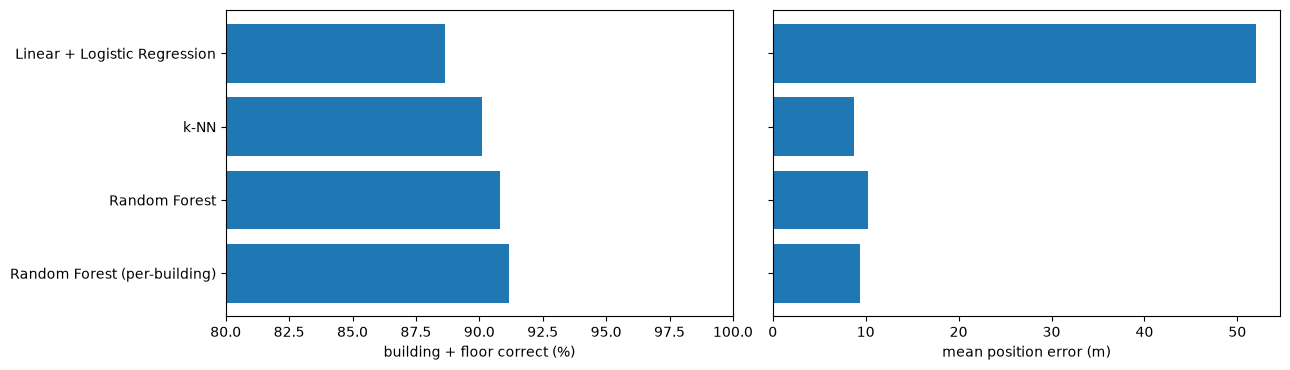

In [26]:
r = results
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].barh(r.index, r.building_floor_acc * 100)
ax[0].set_xlim(80, 100)
ax[0].set_xlabel("building + floor correct (%)")
ax[0].invert_yaxis()
ax[1].barh(r.index, r.mean_error_m)
ax[1].set_xlabel("mean position error (m)")
ax[1].invert_yaxis()
ax[1].set_yticklabels([])
plt.tight_layout()
plt.show()

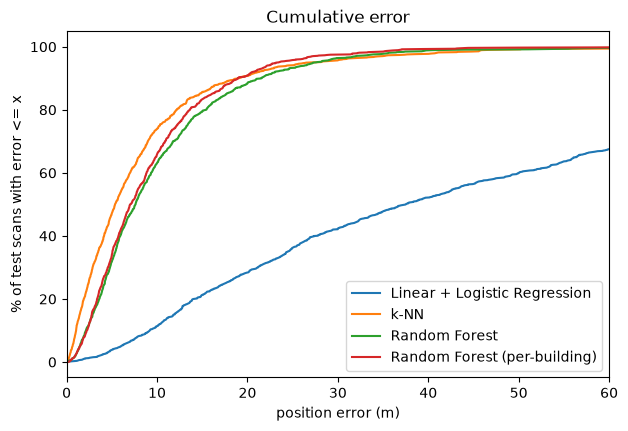

In [27]:
plt.figure(figsize=(7, 4.5))
for name in r.index:
    e = np.sort(positioning_errors(yte, preds[name]))
    plt.plot(e, np.arange(1, len(e) + 1) / len(e) * 100, label=name)
plt.xlim(0, 60)
plt.xlabel("position error (m)")
plt.ylabel("% of test scans with error <= x")
plt.title("Cumulative error")
plt.legend()
plt.show()

What we see:
- Building is easy for all models. Logistic regression even gets 100% because each building has its own APs.
- Linear regression is very bad for position (about 52 m). Position is not a linear function of signal strength.
- k-NN and the per-building Random Forest are close. k-NN has the lowest position error, the per-building forest has the best floor accuracy.
- The per-building forest is better than one global forest (9.4 m vs 10.2 m).
- The original UJIIndoorLoc paper reports 89.9% floor accuracy and 7.9 m error with k-NN, so we are in the same range.

## 7. Error analysis (Random Forest per-building)

In [28]:
rf_pred = preds["Random Forest (per-building)"]
hierarchical_breakdown(yte, rf_pred)

,case,count,mean,median,share_of_total_error
0,"building ok, floor ok",1013,8.570,6.648,0.834
1,"building ok, floor wrong",96,15.728,12.553,0.145
2,building wrong,2,107.255,107.255,0.021


Only 2 scans get the wrong building but they are about 107 m off. A wrong floor almost doubles the position error.

### 7.1 Floor confusion matrices

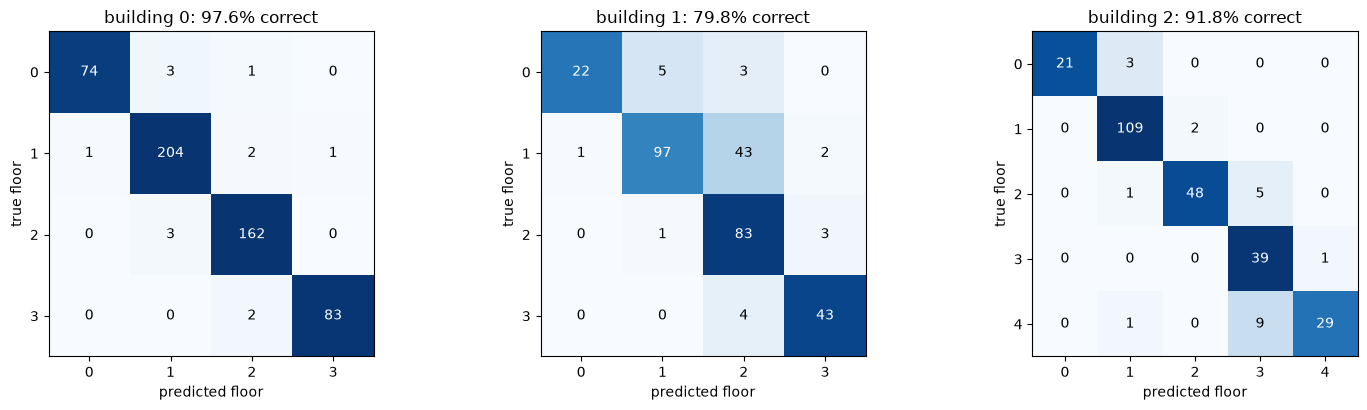

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for b in range(3):
    m = yte.BUILDINGID.to_numpy() == b
    floors = sorted(yte.loc[m, "FLOOR"].unique())
    cm = confusion_matrix(yte.loc[m, "FLOOR"], rf_pred["FLOOR"][m], labels=floors)
    ax[b].imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(len(floors)):
        for j in range(len(floors)):
            ax[b].text(j, i, cm[i, j], ha="center", va="center",
                       color="white" if cm[i, j] > cm[i].sum() * 0.55 else "black")
    ax[b].set_xticks(range(len(floors)), floors)
    ax[b].set_yticks(range(len(floors)), floors)
    ax[b].set_xlabel("predicted floor")
    ax[b].set_ylabel("true floor")
    ax[b].set_title(f"building {b}: {np.trace(cm) / cm.sum() * 100:.1f}% correct")
plt.tight_layout()
plt.show()

Mistakes are almost always to the next floor. The biggest one is building 1, floor 1 predicted as floor 2.

### 7.2 Error map

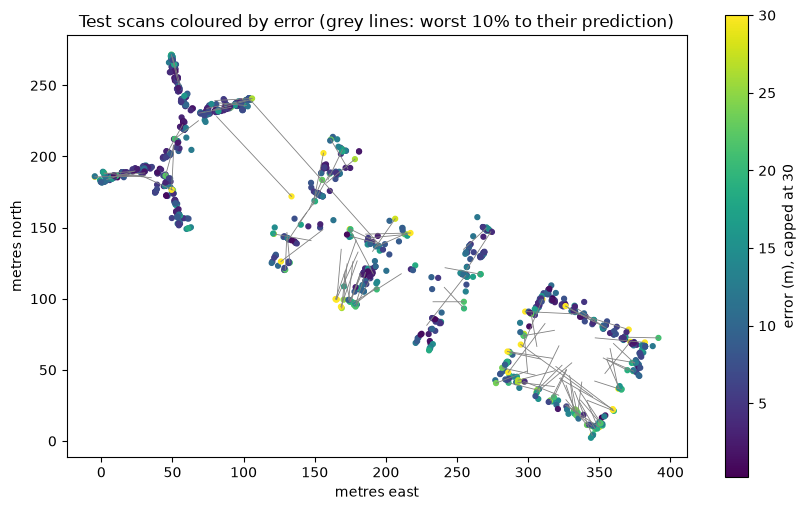

In [30]:
err = positioning_errors(yte, rf_pred)
tx, ty = yte.LONGITUDE - x0, yte.LATITUDE - y0
px, py = rf_pred["LONGITUDE"] - x0, rf_pred["LATITUDE"] - y0

plt.figure(figsize=(10, 6))
worst = np.flatnonzero(err > np.percentile(err, 90))
for i in worst:
    plt.plot([tx.iloc[i], px[i]], [ty.iloc[i], py[i]], color="grey", linewidth=0.6)
plt.scatter(tx, ty, c=np.clip(err, 0, 30), cmap="viridis", s=12)
plt.colorbar(label="error (m), capped at 30")
plt.gca().set_aspect("equal")
plt.xlabel("metres east")
plt.ylabel("metres north")
plt.title("Test scans coloured by error (grey lines: worst 10% to their prediction)")
plt.show()

In [31]:
bf = (yte.BUILDINGID.astype(str) + "-" + yte.FLOOR.astype(str)).rename("building_floor")
per_group_error(yte, rf_pred, bf)

,building_floor,n,mean_error_m,median_error_m,building_floor_acc
0,0-0,78,7.477,6.612,0.949
1,0-1,208,7.298,4.984,0.981
2,0-2,165,6.491,5.344,0.982
3,0-3,85,7.519,6.359,0.976
4,1-0,30,10.176,8.524,0.733
5,1-1,143,10.267,7.832,0.671
6,1-2,87,11.819,8.867,0.954
7,1-3,47,9.795,6.396,0.915
8,2-0,24,12.154,7.451,0.875
9,2-1,111,9.299,7.718,0.982


### 7.3 Error by phone and by number of APs heard

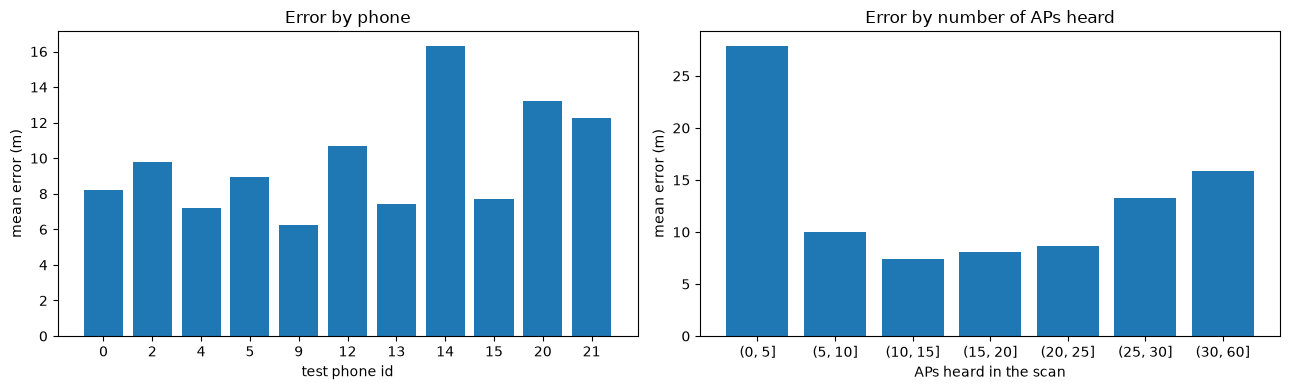

,mean,size
aps_heard,,
"(0, 5]",27.894,18
"(5, 10]",10.017,189
"(10, 15]",7.434,373
"(15, 20]",8.053,246
"(20, 25]",8.698,144
"(25, 30]",13.297,90
"(30, 60]",15.825,51


In [32]:
by_phone = per_group_error(yte, rf_pred, mte["PHONEID"])
n_heard = (Xte != NOT_DETECTED).sum(axis=1)
by_aps = pd.DataFrame({"aps_heard": pd.cut(n_heard, [0, 5, 10, 15, 20, 25, 30, 60]), "error": err}) \
    .groupby("aps_heard", observed=True).error.agg(["mean", "size"])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(by_phone.PHONEID.astype(str), by_phone.mean_error_m)
ax[0].set_xlabel("test phone id")
ax[0].set_ylabel("mean error (m)")
ax[0].set_title("Error by phone")
ax[1].bar(by_aps.index.astype(str), by_aps["mean"])
ax[1].set_xlabel("APs heard in the scan")
ax[1].set_ylabel("mean error (m)")
ax[1].set_title("Error by number of APs heard")
plt.tight_layout()
plt.show()
by_aps

In [33]:
# who are the scans that hear more than 25 APs?
many = n_heard > 25
print("scans hearing > 25 APs:", many.sum())
print(mte.loc[many, "PHONEID"].value_counts().head(3))
print("average APs heard per test phone:")
print(pd.Series(n_heard).groupby(mte.PHONEID.to_numpy()).mean().round(1).sort_values(ascending=False).head(4))

scans hearing > 25 APs: 141
PHONEID
20    105
12     14
13      6
Name: count, dtype: int64
average APs heard per test phone:
20    25.0
12    19.8
9     17.3
21    17.3
dtype: float64


- Scans that hear 5 or fewer APs have the biggest error.
- Error also goes up above 25 APs, but most of those scans come from phone 20, a phone that is not in the training data and is one of the worst phones overall. So this is mostly a device effect.
- Error changes a lot between phones (about 6 m to 16 m), so different phones reading signals differently is a real problem.

### 7.4 Does removing the phone 19 readings help?

In [34]:
keep = ~((Xtr != NOT_DETECTED) & (Xtr > -30)).any(axis=1)
m = HierarchicalModel("rf", features=F(**best_features), max_features=best_mf, n_estimators=300)
m.fit(Xtr[keep], ytr[keep].reset_index(drop=True))
s = summarize(yte, m.predict(Xte))
print("without suspicious scans: error %.2f m, floor acc %.3f" % (s["mean_error_m"], s["building_floor_acc"]))
print("with all scans          : error %.2f m, floor acc %.3f" % (results.loc["Random Forest (per-building)", "mean_error_m"],
                                                                     results.loc["Random Forest (per-building)", "building_floor_acc"]))

without suspicious scans: error 9.46 m, floor acc 0.911
with all scans          : error 9.37 m, floor acc 0.912


No improvement, so we keep all the data. Random Forest is not affected much by these few odd values.

### 7.5 Feature importance

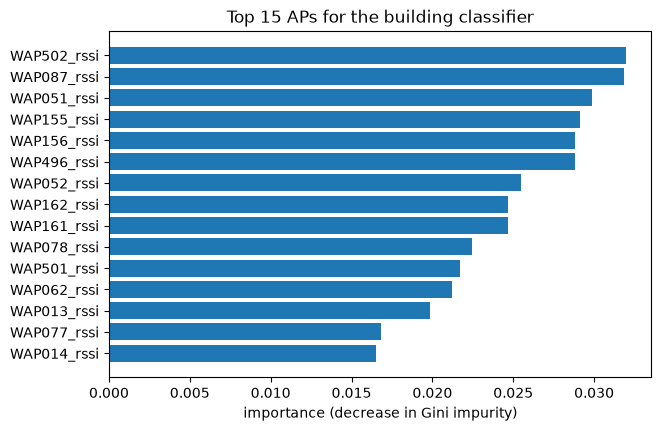

In [35]:
rf_model = models["Random Forest (per-building)"]
names = rf_model.fe_.get_feature_names_out()
imp = pd.Series(rf_model.building_.model_.feature_importances_, index=names).sort_values(ascending=False).head(15)

plt.figure(figsize=(7, 4.5))
plt.barh(imp.index[::-1], imp.values[::-1])
plt.xlabel("importance (decrease in Gini impurity)")
plt.title("Top 15 APs for the building classifier")
plt.show()

## 8. Summary and gap for Phase 2

- Replacing +100 with -105 is the most important preprocessing step. Extra features did not help.
- Per-building Random Forest: 99.8% building, 91.3% floor, about 9.4 m mean error on the test set. k-NN is very close.
- Most errors come from neighbouring floors, scans that hear very few APs, and phones not seen in training.

Gap: our models learn building, floor and position separately. They do not share what they learn, and the per-building model can only pass the building decision forward. In Phase 2 we will train one neural network with a shared part and three outputs (building, floor, position) and compare it with these results on the same split.